In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
raw = pd.read_excel(url)
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print(raw.isnull().sum())

df = raw.dropna(subset=["CustomerID"])
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["Total"] = df["Quantity"] * df["UnitPrice"]

print("Rows after cleaning:", df.shape[0])

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Rows after cleaning: 397884


In [4]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Total", "sum"))

print("Customers:", rfm.shape[0])
rfm.describe().round(1)

Customers: 4338


,Recency,Frequency,Monetary
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2054.3
std,100.0,7.7,8989.2
min,1.0,1.0,3.8
25%,18.0,1.0,307.4
50%,51.0,2.0,674.5
75%,142.0,5.0,1661.7
max,374.0,209.0,280206.0


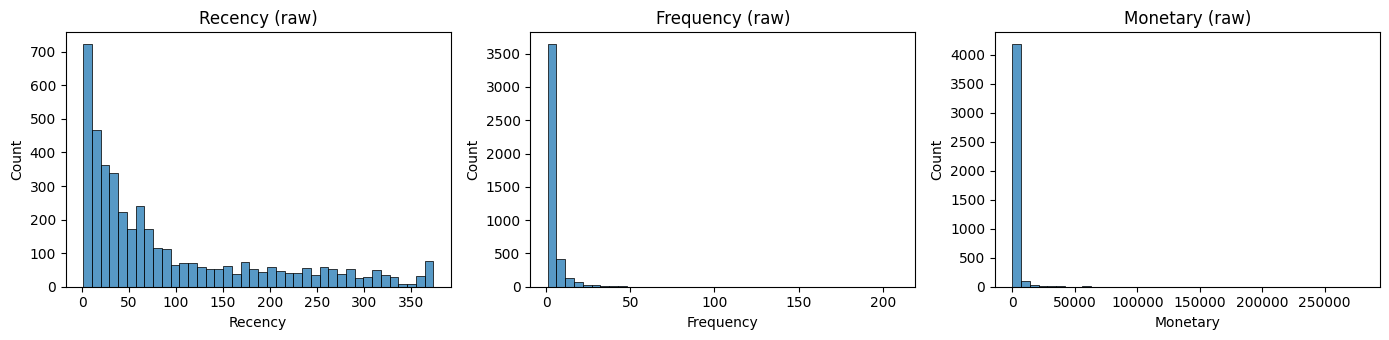

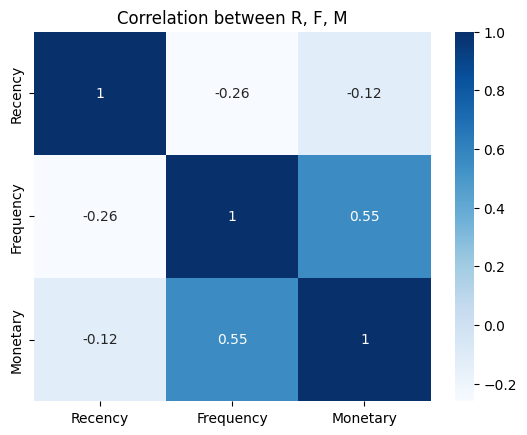

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, rfm.columns):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(col + " (raw)")
plt.tight_layout(); plt.show()

sns.heatmap(rfm.corr(), annot=True, cmap="Blues")
plt.title("Correlation between R, F, M")
plt.show()

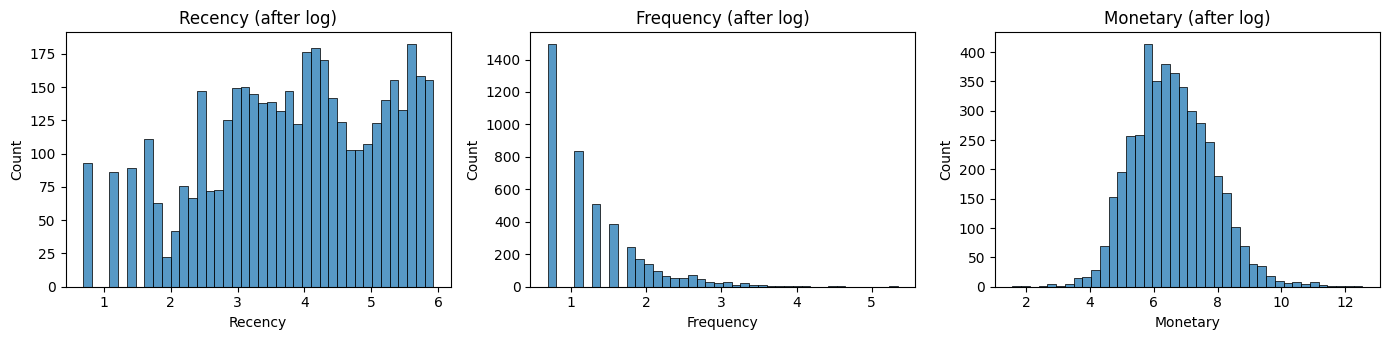

In [6]:
rfm_log = np.log1p(rfm)
X = StandardScaler().fit_transform(rfm_log)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, rfm_log.columns):
    sns.histplot(rfm_log[col], bins=40, ax=ax)
    ax.set_title(col + " (after log)")
plt.tight_layout(); plt.show()

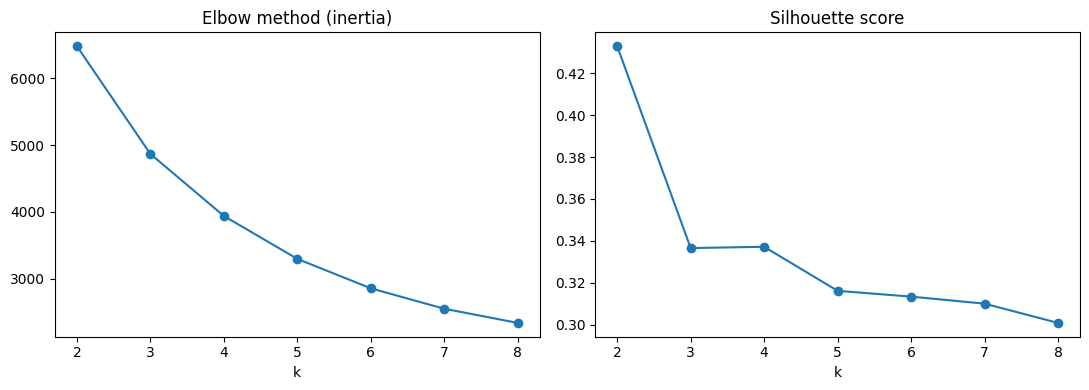

In [7]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("Elbow method (inertia)")
axes[1].plot(ks, sils, marker="o");     axes[1].set_title("Silhouette score")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.show()

In [8]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X)

print("K-Means silhouette:", round(silhouette_score(X, km_labels), 3))
print(pd.Series(km_labels).value_counts().sort_index())

K-Means silhouette: 0.337
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64


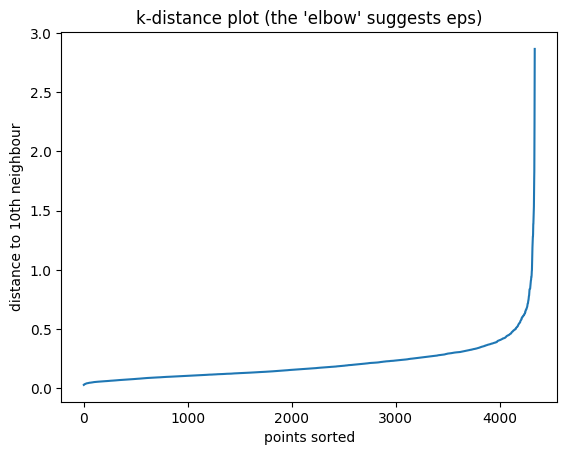

DBSCAN clusters: 2 | noise points: 79
-1      79
 0    2780
 1    1479
Name: count, dtype: int64


In [9]:
min_samples = 10
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
plt.plot(np.sort(distances[:, -1]))
plt.title("k-distance plot (the 'elbow' suggests eps)")
plt.ylabel("distance to 10th neighbour"); plt.xlabel("points sorted")
plt.show()

eps = 0.5
db_labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()
print("DBSCAN clusters:", n_clusters, "| noise points:", n_noise)
print(pd.Series(db_labels).value_counts().sort_index())

Variance explained by PC1, PC2: [0.751 0.188] | total: 0.939


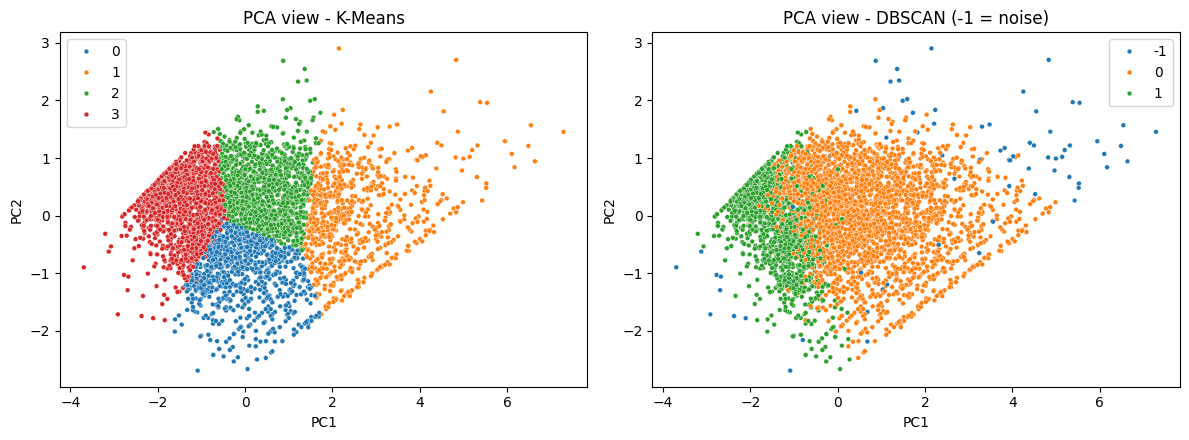

     Recency  Frequency  Monetary
PC1    -0.51       0.62      0.60
PC2     0.85       0.26      0.46


In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, labels, title in zip(axes, [km_labels, db_labels], ["K-Means", "DBSCAN (-1 = noise)"]):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels,
                    palette="tab10", s=12, ax=ax)
    ax.set_title("PCA view - " + title)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

print(pd.DataFrame(pca.components_, columns=rfm.columns, index=["PC1", "PC2"]).round(2))

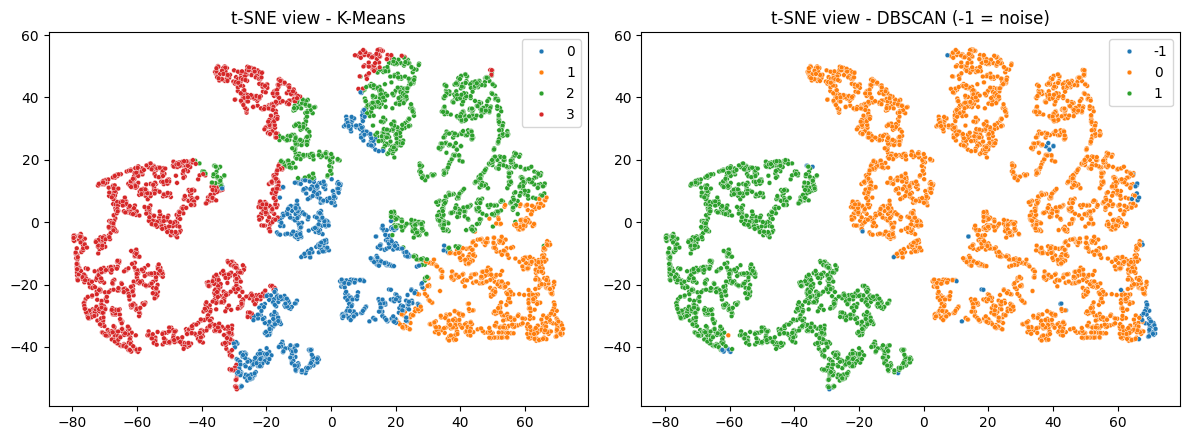

In [11]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42)
X_tsne = tsne.fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, labels, title in zip(axes, [km_labels, db_labels], ["K-Means", "DBSCAN (-1 = noise)"]):
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=labels,
                    palette="tab10", s=12, ax=ax)
    ax.set_title("t-SNE view - " + title)
plt.tight_layout(); plt.show()

In [12]:
mask = db_labels != -1
db_sil = (silhouette_score(X[mask], db_labels[mask])
          if len(set(db_labels[mask])) > 1 else float("nan"))

compare = pd.DataFrame({
    "Clusters":   [K, n_clusters],
    "Noise points": [0, n_noise],
    "Silhouette": [silhouette_score(X, km_labels), db_sil],
}, index=["K-Means", "DBSCAN"]).round(3)
print(compare)

         Clusters  Noise points  Silhouette
K-Means         4             0       0.337
DBSCAN          2            79       0.294


         Customers  Recency  Frequency  Monetary  Customers %  Revenue %
Cluster                                                                 
0              837     18.1        2.1     551.8         19.3        5.2
1              716     12.1       13.7    8074.3         16.5       64.9
2             1173     71.1        4.1    1802.8         27.0       23.7
3             1612    182.5        1.3     343.5         37.2        6.2


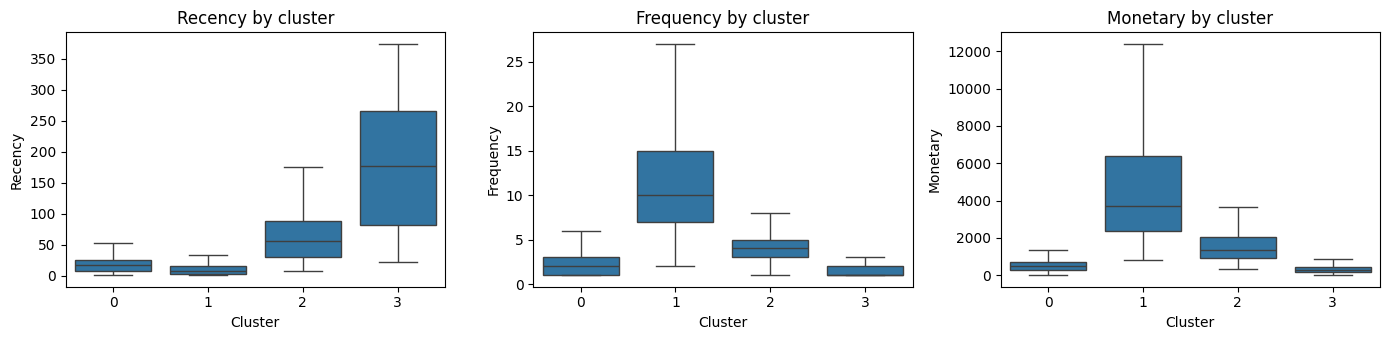

In [13]:
rfm["Cluster"] = km_labels

profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean")).round(1)
profile["Customers %"] = (profile["Customers"] / len(rfm) * 100).round(1)
profile["Revenue %"] = (rfm.groupby("Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100).round(1)
print(profile)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(x="Cluster", y=col, data=rfm, showfliers=False, ax=ax)
    ax.set_title(col + " by cluster")
plt.tight_layout(); plt.show()

In [14]:
med = rfm[["Recency", "Frequency", "Monetary"]].median()

def persona(r):
    recent   = r.Recency   < med.Recency
    frequent = r.Frequency > med.Frequency
    big      = r.Monetary  > med.Monetary
    if recent and frequent and big: return "Champions"
    if recent and frequent:         return "Loyal regulars"
    if recent:                      return "New / promising"
    if frequent or big:             return "At-risk (past good customers)"
    return "Lost / hibernating"

actions = {
    "Champions": "VIP perks, early access, referral rewards. Do not discount.",
    "Loyal regulars": "Loyalty points, bundles and upsell to raise basket size.",
    "New / promising": "Welcome series, second-purchase coupon, product recommendations.",
    "At-risk (past good customers)": "Win-back email, personal offer, 'we miss you' campaign.",
    "Lost / hibernating": "Low-cost reactivation or a last-chance email, then stop spending on them.",
}

profile["Persona"] = profile[["Recency", "Frequency", "Monetary"]].apply(persona, axis=1)
profile["Marketing action"] = profile["Persona"].map(actions)
print(profile[["Customers %", "Revenue %", "Persona", "Marketing action"]].to_string())

         Customers %  Revenue %                        Persona                                                           Marketing action
Cluster                                                                                                                                  
0               19.3        5.2                 Loyal regulars                   Loyalty points, bundles and upsell to raise basket size.
1               16.5       64.9                      Champions                VIP perks, early access, referral rewards. Do not discount.
2               27.0       23.7  At-risk (past good customers)                    Win-back email, personal offer, 'we miss you' campaign.
3               37.2        6.2             Lost / hibernating  Low-cost reactivation or a last-chance email, then stop spending on them.


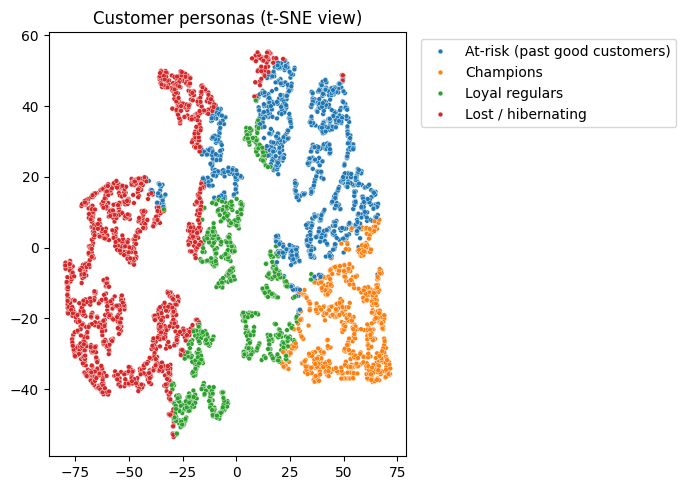

In [15]:
rfm["Persona"] = rfm["Cluster"].map(profile["Persona"])

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=rfm["Persona"], palette="tab10", s=12)
plt.title("Customer personas (t-SNE view)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()